# Human PBMCs (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-08
> - Modified: 2025-12-21
> - https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high

# Experimental Design

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donor | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 25-30 | Healthy | 10X 3' V3.1 scRNA-seq | AllCells |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger 6.1.0 with --expect-cells = 10000

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(monocle3))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [3]:
# # load data from umi matrix
# scrna <- new_cell_data_set(
#     expression_data = as(umi_matrix, "sparseMatrix"),
#     cell_metadata = cell_metadata,
#     gene_metadata = gene_annotation)

# # load data from cell Ranger
# # ${data_dir}/outs/filtered_feature_bc_matrix
# scrna <- load_cellranger_data(data_dir, umi_cutoff = 0)

# load data from cell Ranger
scrna <- load_mm_data(
    mat_path = file.path(
        data_dir, "matrix", "filtered_feature_bc_matrix", "matrix.mtx.gz"),
    feature_anno_path = file.path(
        data_dir, "matrix", "filtered_feature_bc_matrix", "features.tsv.gz"), 
    feature_metadata_column_names = c("gene_short_name", "notes"),
    cell_anno_path = file.path(
        data_dir, "matrix", "filtered_feature_bc_matrix", "barcodes.tsv.gz"),
    umi_cutoff = 0)

In [4]:
scrna

class: cell_data_set 
dim: 36601 11996 
metadata(1): cds_version
assays(1): counts
rownames(36601): ENSG00000243485 ENSG00000237613 ... ENSG00000278817
  ENSG00000277196
rowData names(2): gene_short_name notes
colnames(11996): AAACCCAAGGCCCAAA-1 AAACCCAAGTAATACG-1 ...
  TTTGTTGTCTACACAG-1 TTTGTTGTCTCATTAC-1
colData names(3): cell Size_Factor n.umi
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

# 2. Quality Control (Skip)

In [5]:
seurat <- readRDS(file.path(
    data_dir, "result", "s3_normalization_seurat_V5.rds"))
seurat

An object of class Seurat 
42275 features across 10087 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT

In [6]:
scrna <- new_cell_data_set(
    expression_data = LayerData(
        seurat, assay = "RNA", layer = "counts"),
    cell_metadata = DataFrame(
        row.names = Cells(seurat),
        cell = Cells(seurat)),
    gene_metadata = DataFrame(
        row.names = Features(seurat), 
        gene_short_name = Features(seurat)))

In [7]:
scrna

class: cell_data_set 
dim: 22302 10087 
metadata(1): cds_version
assays(1): counts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(1): gene_short_name
colnames(10087): AAACCCAAGTAATACG-1 AAACCCAAGTCACACT-1 ...
  TTTGTTGTCCATTTCA-1 TTTGTTGTCTACACAG-1
colData names(2): cell Size_Factor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

# 3. Normalization

## PCA

In [8]:
## Step 1: Normalize and pre-process the data
scrna <- preprocess_cds(
    scrna, method = "PCA", norm_method = "log", 
    scaling = TRUE, num_dim = 50)
scrna

class: cell_data_set 
dim: 22302 10087 
metadata(1): cds_version
assays(1): counts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(1): gene_short_name
colnames(10087): AAACCCAAGTAATACG-1 AAACCCAAGTCACACT-1 ...
  TTTGTTGTCCATTTCA-1 TTTGTTGTCTACACAG-1
colData names(2): cell Size_Factor
reducedDimNames(1): PCA
mainExpName: NULL
altExpNames(0):

Warning message:
“`qplot()` was deprecated in ggplot2 3.4.0.
ℹ The deprecated feature was likely used in the monocle3 package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the monocle3 package.
  Please report the issue to the authors.”


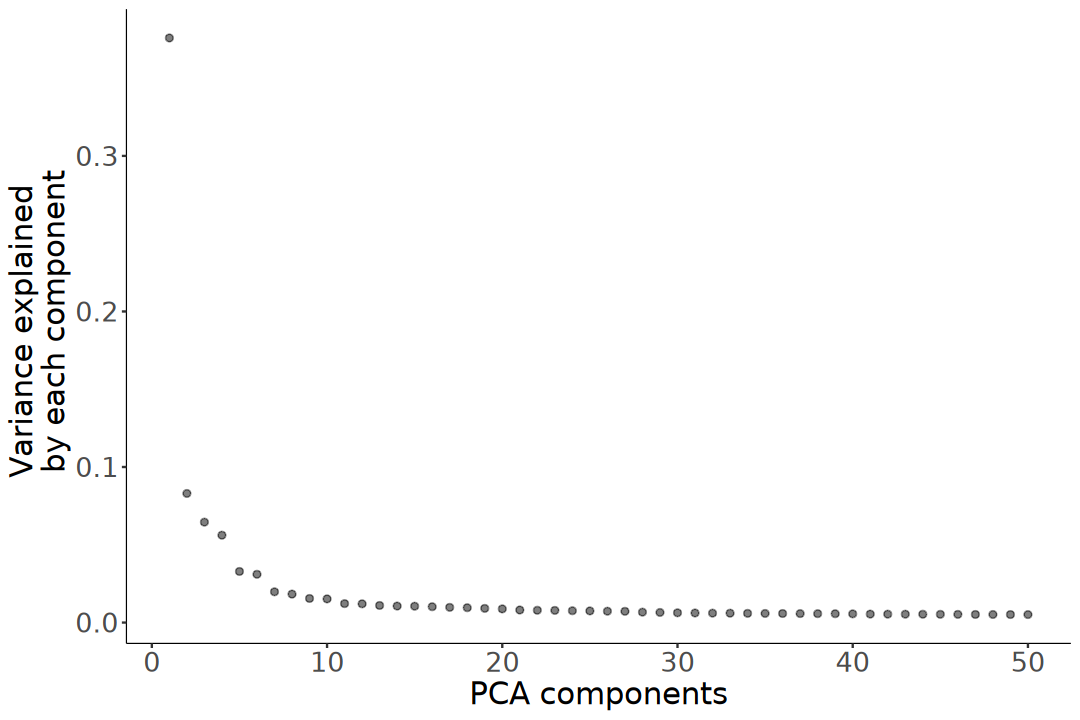

In [9]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
plot_pc_variance_explained(scrna) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

In [10]:
# Estimating PCA dimensionality
pca_var <- scrna@reduce_dim_aux$PCA$model$svd_sdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 32


In [11]:
nPCs <- 30

# 4. Integration (Skip)

In [12]:
# cds <- align_cds(cds, num_dim = 50, alignment_group = "plate")

# 5. Dimensionality Reduction

## UMAP

In [13]:
# UMAP
scrna <- reduce_dimension(
    scrna, preprocess_method = "PCA")
scrna

class: cell_data_set 
dim: 22302 10087 
metadata(2): cds_version citations
assays(1): counts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(1): gene_short_name
colnames(10087): AAACCCAAGTAATACG-1 AAACCCAAGTCACACT-1 ...
  TTTGTTGTCCATTTCA-1 TTTGTTGTCTACACAG-1
colData names(2): cell Size_Factor
reducedDimNames(2): PCA UMAP
mainExpName: NULL
altExpNames(0):

## t-SNE

In [14]:
# t-SNE
scrna <- reduce_dimension(
    scrna, preprocess_method = "PCA", 
    reduction_method = "tSNE")
scrna

class: cell_data_set 
dim: 22302 10087 
metadata(2): cds_version citations
assays(1): counts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(1): gene_short_name
colnames(10087): AAACCCAAGTAATACG-1 AAACCCAAGTCACACT-1 ...
  TTTGTTGTCCATTTCA-1 TTTGTTGTCTACACAG-1
colData names(2): cell Size_Factor
reducedDimNames(3): PCA UMAP tSNE
mainExpName: NULL
altExpNames(0):

# 6. Clustering

In [15]:
scrna <- cluster_cells(
    scrna, reduction_method = "UMAP", k = 20,
    cluster_method = "leiden", resolution = 1e-5)
scrna

class: cell_data_set 
dim: 22302 10087 
metadata(2): cds_version citations
assays(1): counts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(1): gene_short_name
colnames(10087): AAACCCAAGTAATACG-1 AAACCCAAGTCACACT-1 ...
  TTTGTTGTCCATTTCA-1 TTTGTTGTCTACACAG-1
colData names(2): cell Size_Factor
reducedDimNames(3): PCA UMAP tSNE
mainExpName: NULL
altExpNames(0):

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the monocle3 package.
  Please report the issue to the authors.”


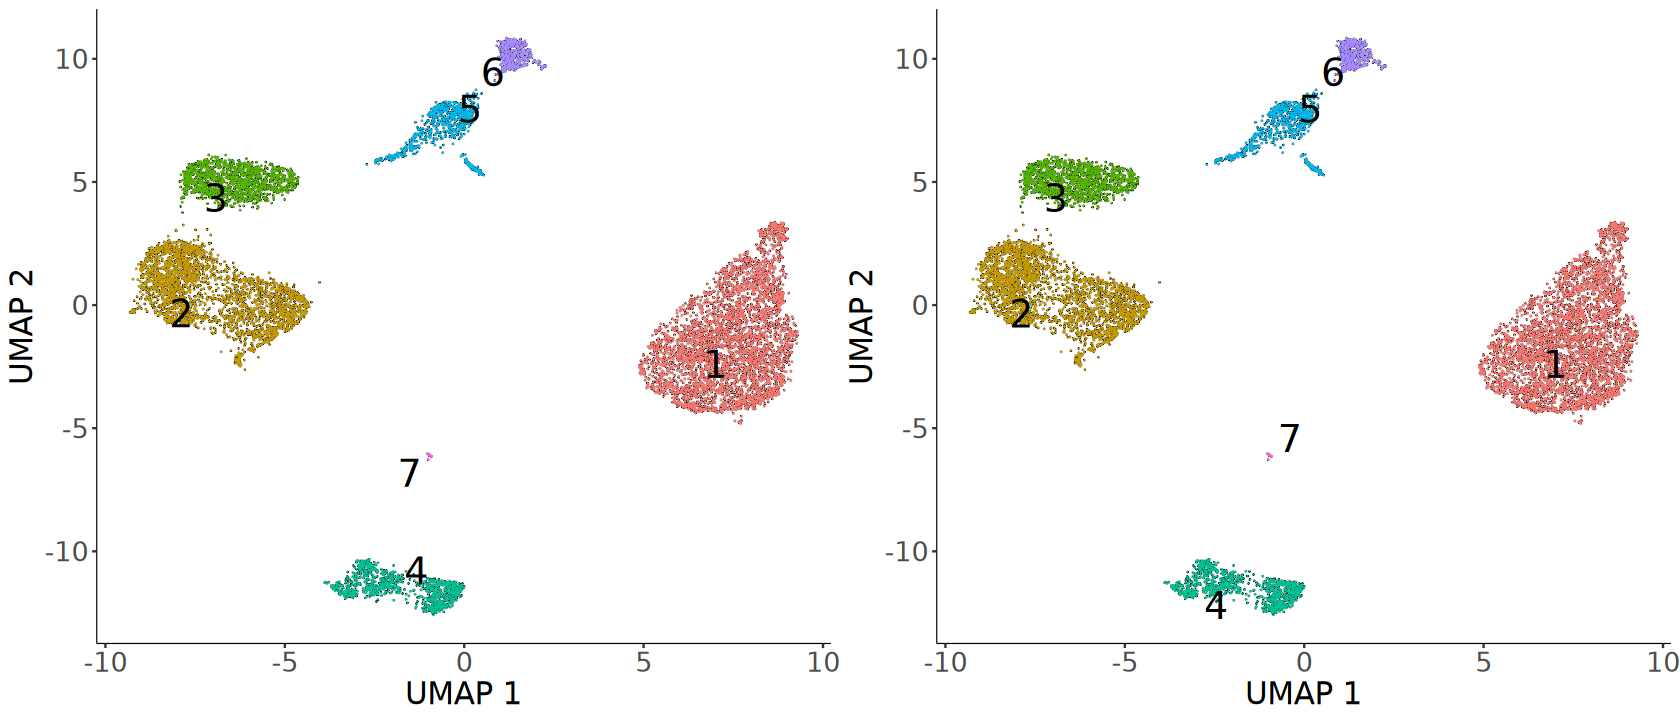

In [16]:
p1 <- plot_cells(scrna, reduction_method = "UMAP", 
                 show_trajectory_graph = FALSE, 
                 cell_size = 0.2, group_label_size = 8) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))
p2 <- plot_cells(scrna, reduction_method = "UMAP", 
                 color_cells_by = "partition", 
                 group_cells_by = "partition",
                 show_trajectory_graph = FALSE, 
                 cell_size = 0.2, group_label_size = 8) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 7. Cluster Biomarkers

In [17]:
sc.markers <- top_markers(
    scrna, group_cells_by = "cluster",
    reduction_method = "UMAP", cores = 1)

  |=======================================================| 100%, Elapsed 00:08


In [18]:
head(sc.markers)

,gene_id,gene_short_name,cell_group,marker_score,mean_expression,fraction_expressing,specificity,pseudo_R2,marker_test_p_value,marker_test_q_value
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,TNFRSF18,TNFRSF18,7,0.4079777,1.998454,0.6923077,0.5893011,0.25538140,1.301735e-21,2.032190e-16
2,EFHD2,EFHD2,6,0.4346165,6.371388,0.9690476,0.4484986,0.39905667,2.196982e-274,3.429796e-269
3,RPL11,RPL11,2,0.2269567,49.822361,0.9992535,0.2271263,0.40674101,0.000000e+00,0.000000e+00
4,RCAN3,RCAN3,2,0.2256543,1.309875,0.6215006,0.3630798,0.22639985,0.000000e+00,0.000000e+00
5,LDLRAP1,LDLRAP1,3,0.2684854,1.168772,0.6725596,0.3991995,0.20491776,1.919912e-257,2.997251e-252
6,SH3BGRL3,SH3BGRL3,5,0.2386876,12.263021,0.9923274,0.2405331,0.07665485,7.901092e-74,1.233471e-68


In [19]:
sc.markers.filt <- sc.markers |> 
    filter(marker_test_q_value < 0.05,
           fraction_expressing > 0.10)

In [20]:
sc.markers.filt |> 
    group_by(cell_group) |> 
    summarise(length(gene_short_name)) |>
    t()

cell_group,1,2,3,4,5,6,7
length(gene_short_name),25,25,25,25,25,25,24


In [21]:
top10 <- sc.markers.filt |> 
    group_by(cell_group) |> 
    top_n(10, wt = pseudo_R2)

top3 <- sc.markers.filt |> 
    group_by(cell_group) |> 
    top_n(3, wt = pseudo_R2)

## Visualization

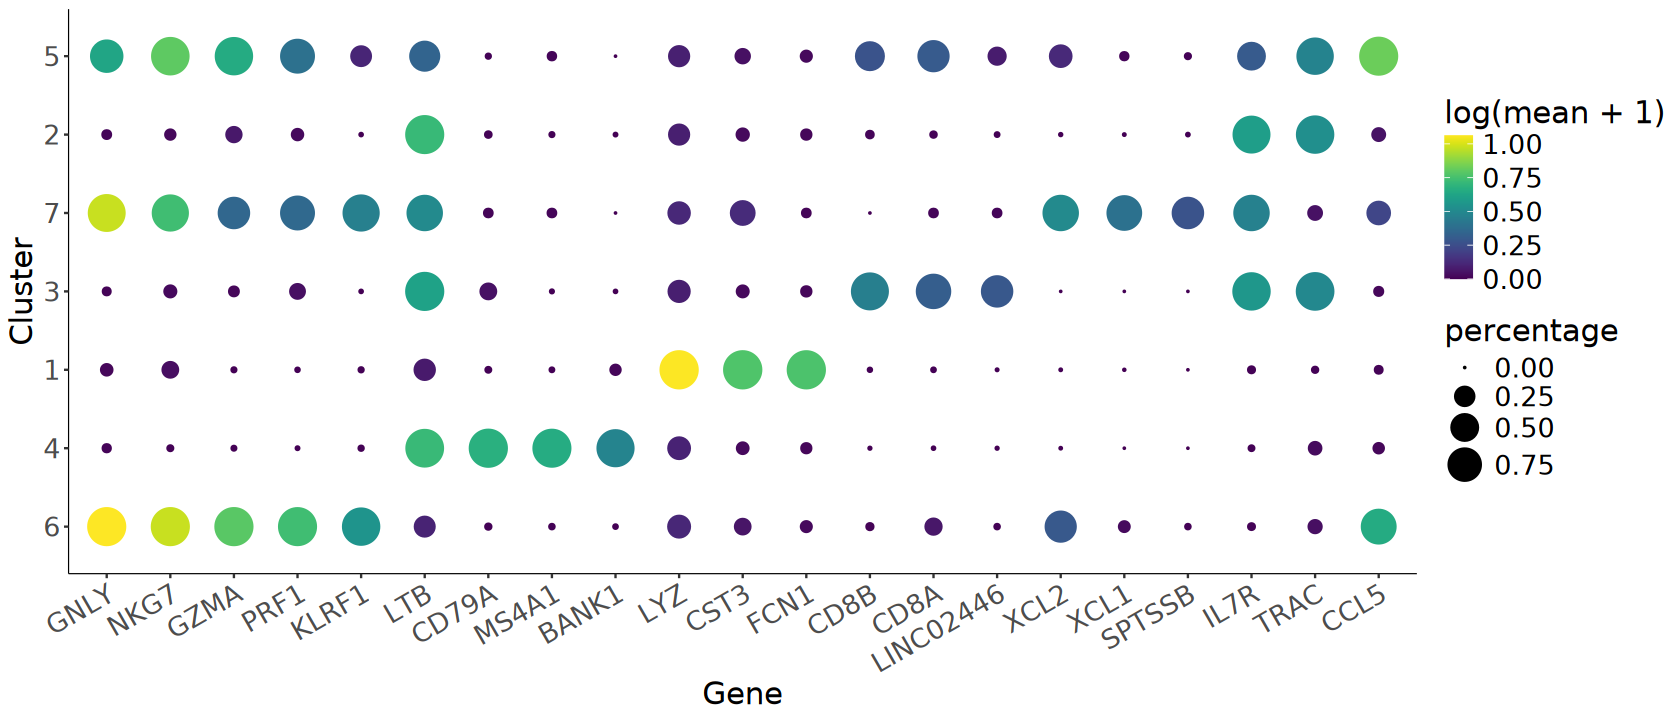

In [22]:
options(repr.plot.width = 14, repr.plot.height = 6)
plot_genes_by_group(scrna, unique(top3$gene_short_name), 
                    group_cells_by = "cluster", 
                    reduction_method = "UMAP",
                    axis_order = "marker_group", 
                    ordering_type = "maximal_on_diag", 
                    max.size = 10) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

# 8. Cell-type Annotation

## Manual Annotation

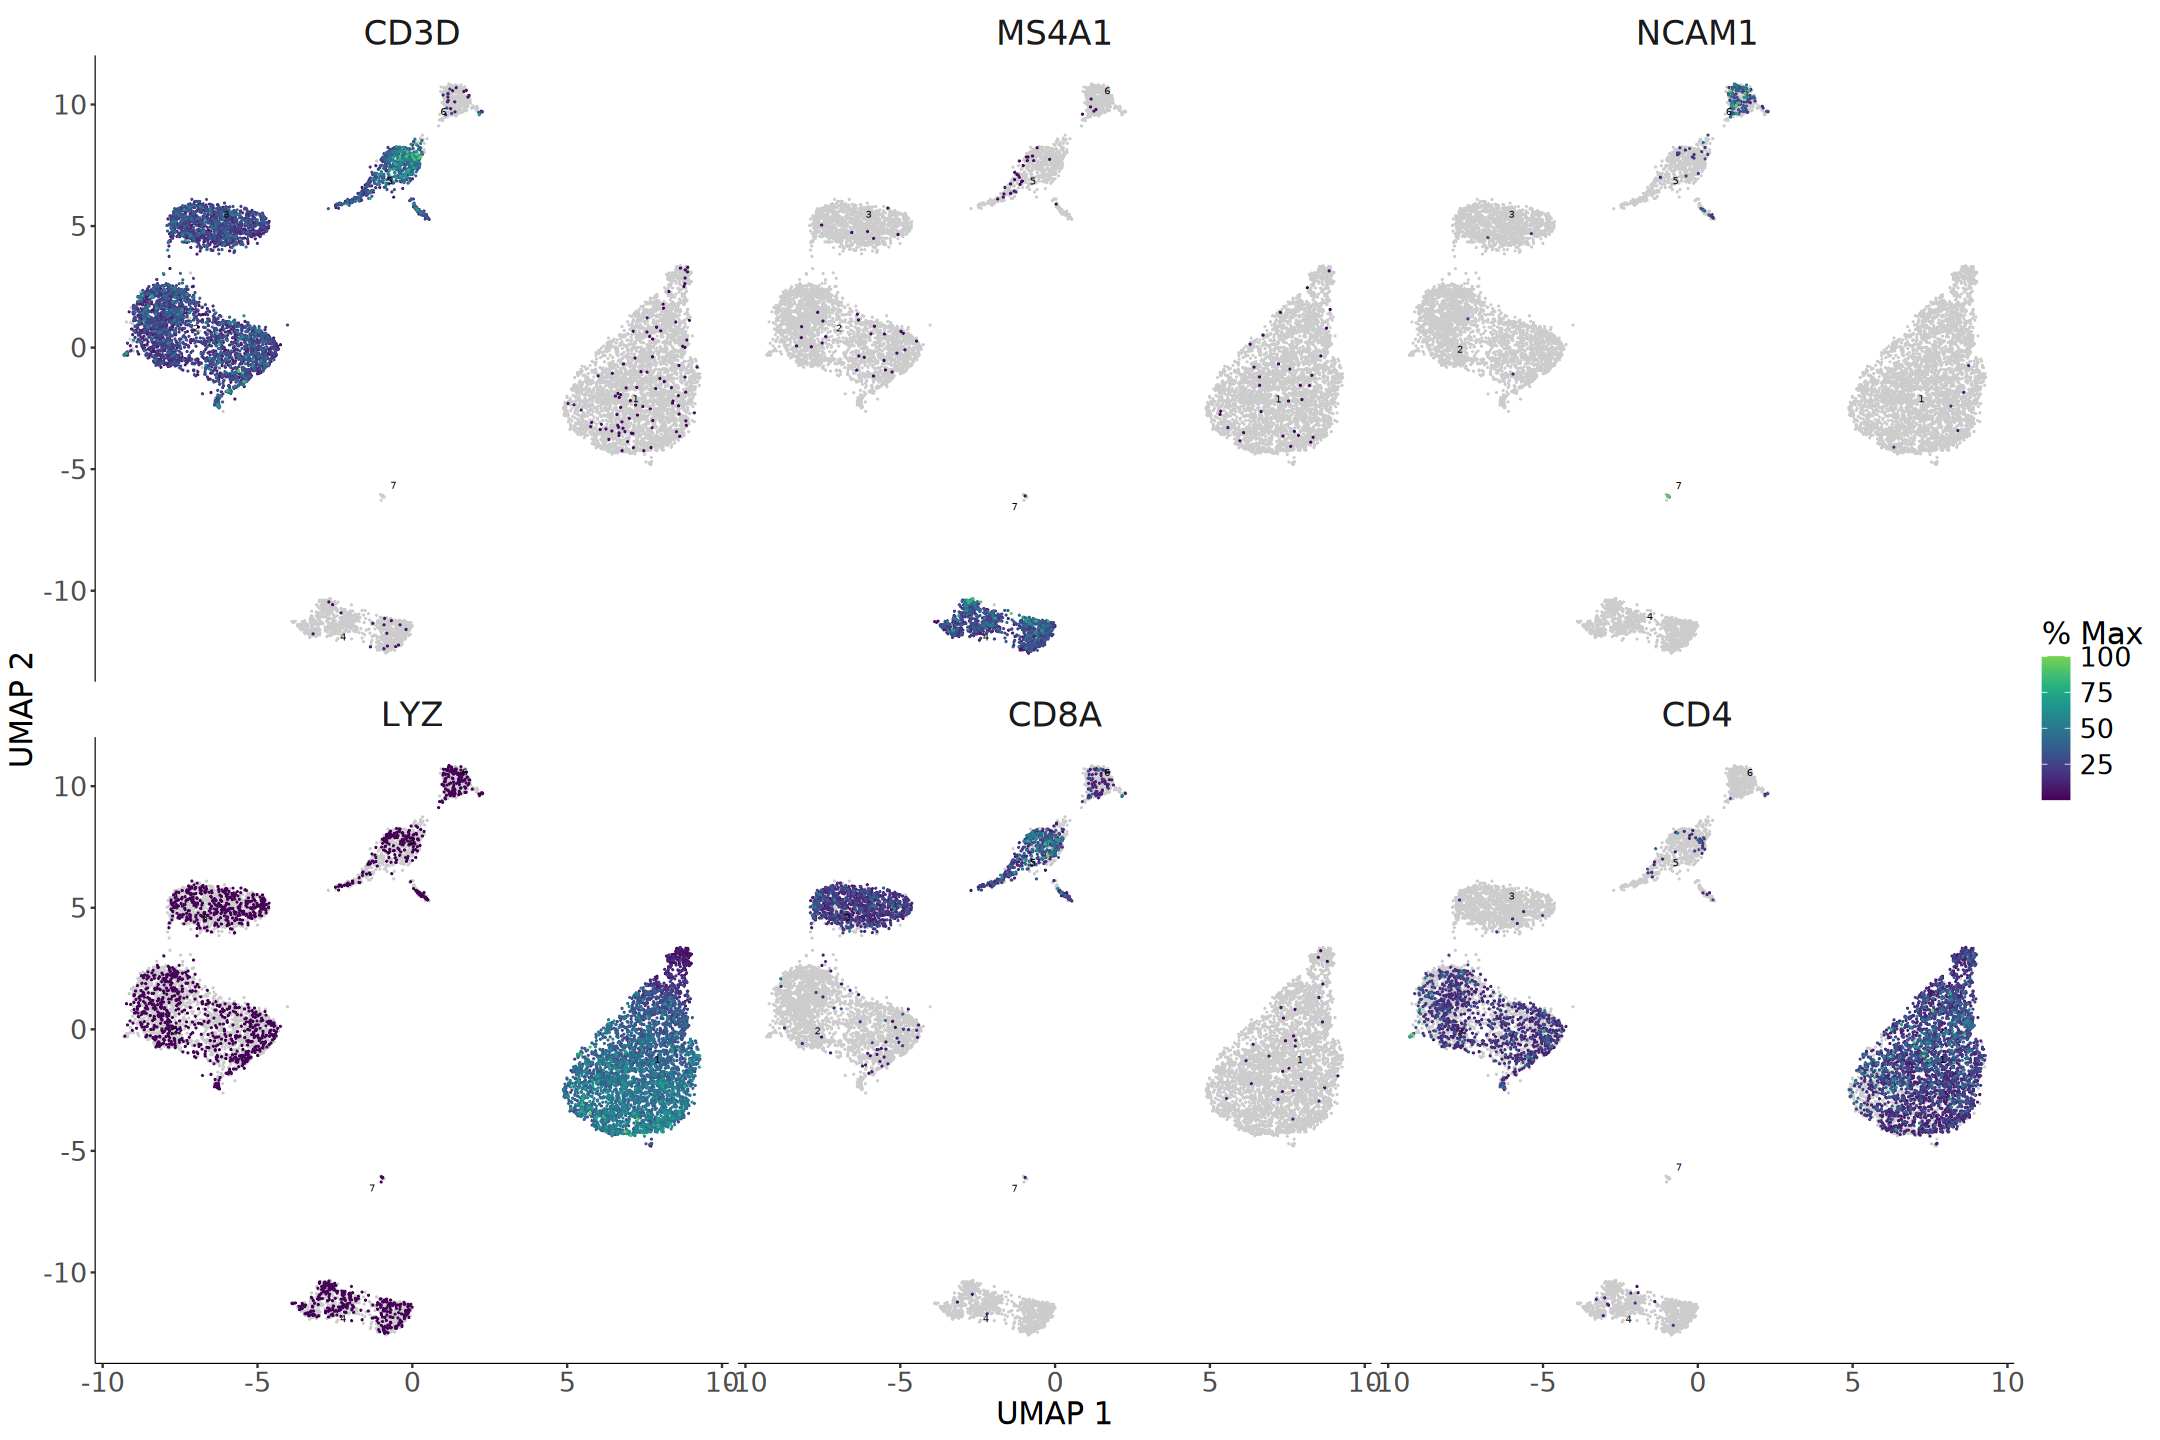

In [23]:
geneset <- c("CD3D", "MS4A1", "NCAM1", "LYZ", "CD8A", "CD4")

options(repr.plot.width = 18, repr.plot.height = 12)
plot_cells(scrna, genes = geneset, show_trajectory_graph = FALSE, 
           graph_label_size = 8) +
    theme(strip.text = element_text(size = 20),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

In [24]:
gene_list <- sc.markers.filt |>
    group_by(cell_group) |>
    top_n(10, wt = pseudo_R2) |>
    summarise(genes = paste0('"', gene_short_name, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cell_group, ": ", genes)) |> 
    pull(out)

In [25]:
gene_list |> cat(sep = "\n")

cluster_1: "S100A9", "S100A8", "MNDA", "NCF2", "CSTA", "FGL2", "FCN1", "LYZ", "SERPINA1", "CST3"
cluster_2: "RPS27", "IL7R", "LTB", "CD3E", "CD3D", "CD3G", "LDHB", "TRAC", "RPS29", "BCL11B"
cluster_3: "GAS5", "CD8A", "CD8B", "LEF1", "NPM1", "CD3E", "CD3D", "LINC02446", "LDHB", "CCR7"
cluster_4: "RALGPS2", "BANK1", "CD74", "MS4A1", "IGHD", "IGHM", "LINC00926", "CD79B", "CD79A", "TNFRSF13C"
cluster_5: "LINC01871", "GZMA", "TRGC2", "KLRG1", "GZMH", "IL32", "CCL5", "HCST", "NKG7", "CST7"
cluster_6: "GNLY", "SPON2", "GZMA", "CLIC3", "PRF1", "KLRF1", "KLRD1", "GZMB", "NKG7", "CST7"
cluster_7: "XCL2", "XCL1", "GNLY", "IL18R1", "CMC1", "SPTSSB", "CTSW", "NCAM1", "TRDC", "IL2RB"


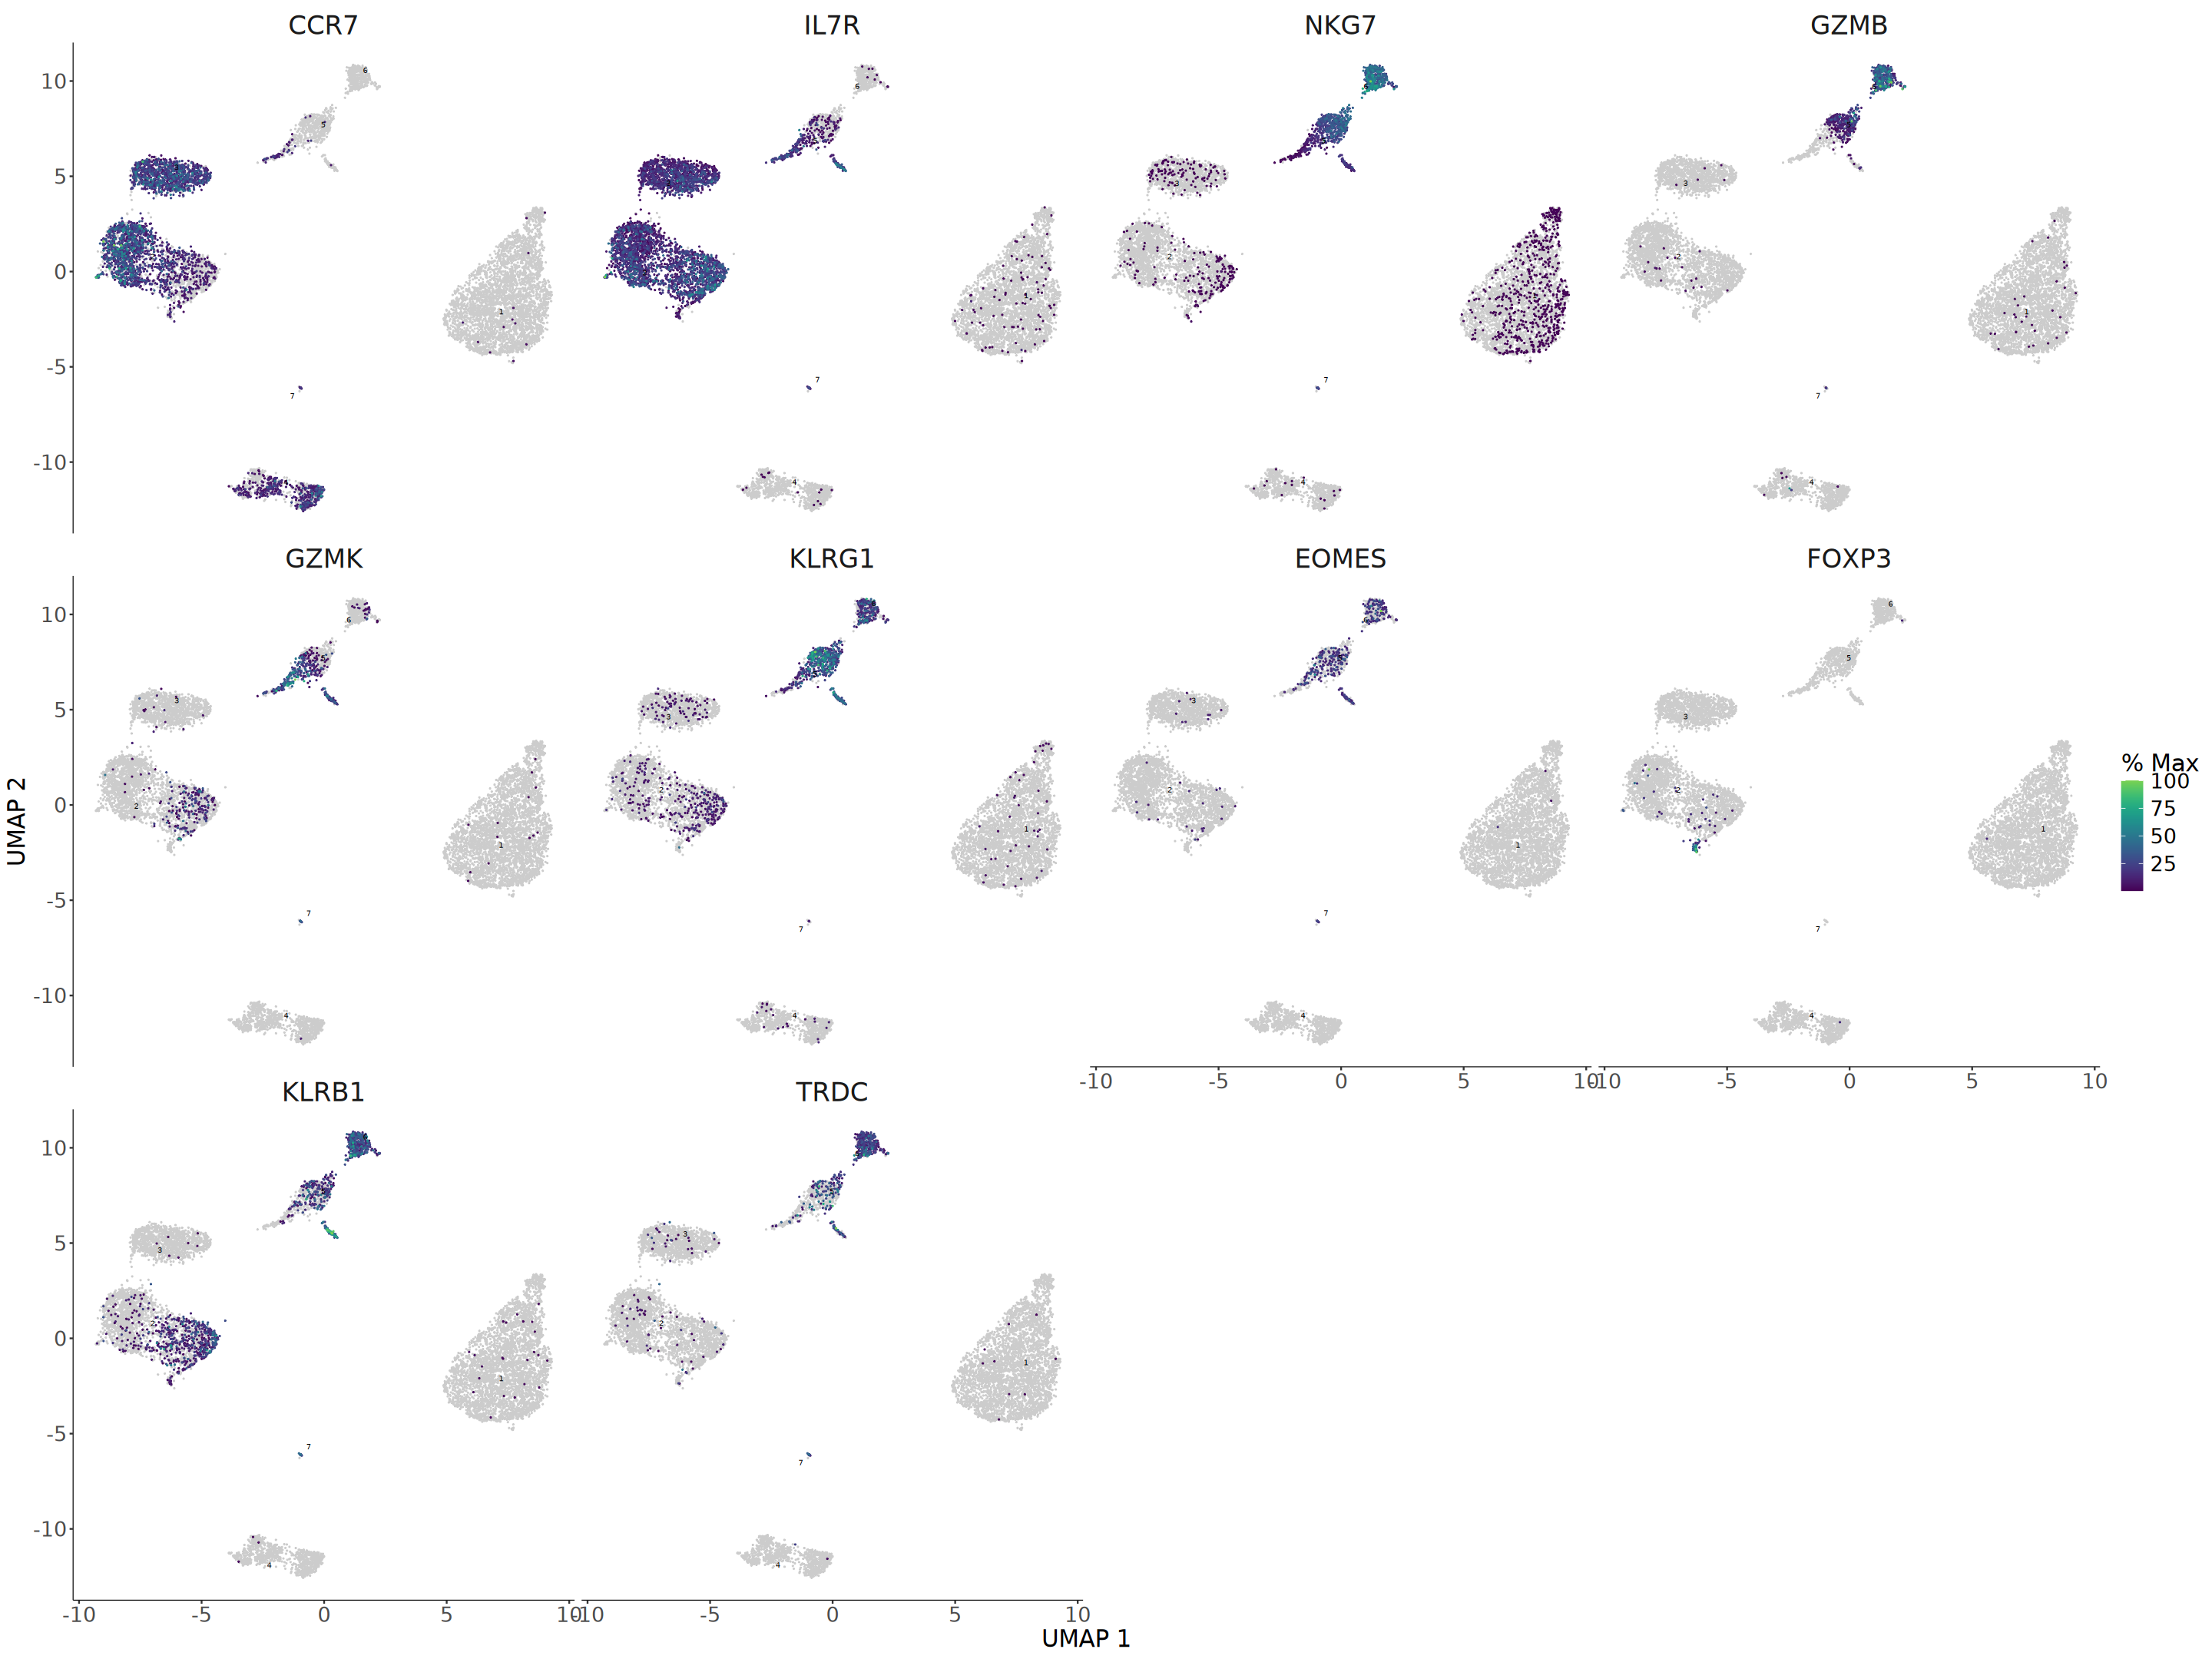

In [26]:
geneset <- c("CCR7", "IL7R", "NKG7", "GZMB", "GZMK",
             "KLRG1", "EOMES", "FOXP3", "KLRB1", "TRDC")

options(repr.plot.width = 24, repr.plot.height = 18)
plot_cells(scrna, genes = geneset, show_trajectory_graph = FALSE, 
           graph_label_size = 8) +
    theme(strip.text = element_text(size = 20),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

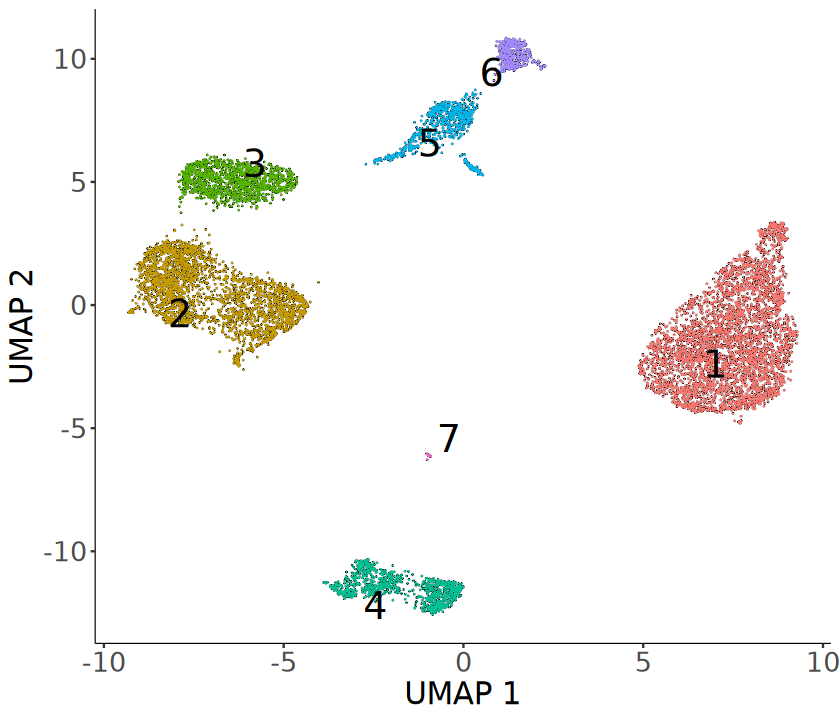

In [27]:
options(repr.plot.width = 7, repr.plot.height = 6)
plot_cells(scrna, reduction_method = "UMAP", 
           show_trajectory_graph = FALSE, 
           cell_size = 0.2, group_label_size = 8) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

In [28]:
colData(scrna)$assigned_cell_type <- as.character(clusters(scrna))

In [29]:
colData(scrna)$assigned_cell_type <- dplyr::recode(
    colData(scrna)$assigned_cell_type,
    "1" = "Monocytes",
    "2" = "CD4 T",
    "3" = "Naïve CD8 T",
    "4" = "B Cells",
    "5" = "Cytotoxic CD8 T",
    "6" = "NK Cells",
    "7" = "Platelets")

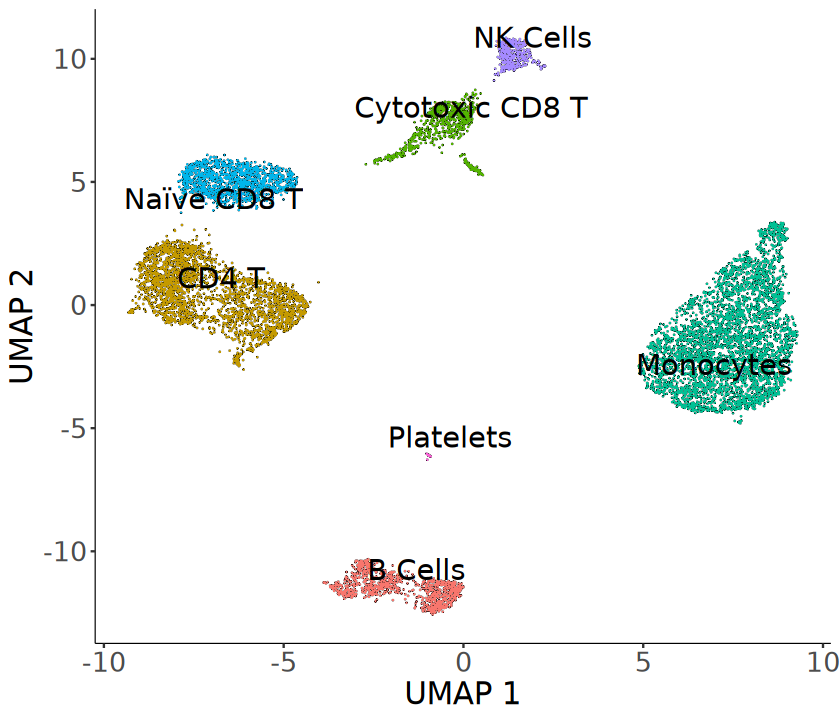

In [30]:
options(repr.plot.width = 7, repr.plot.height = 6)
plot_cells(scrna, reduction_method = "UMAP", 
           color_cells_by = "assigned_cell_type", 
           show_trajectory_graph = FALSE, 
           cell_size = 0.2, group_label_size = 6) +
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))